**Assignment #2: Text Features and Rating Prediction (100 points)**

- **Instructor:** Jaeung Sim (University of Connecticut)
- **Course:** OPIM 5671 Data Mining and Time Series Forecasting
- **Last updated:** October 27, 2026

Companion: `05_Text_Features_and_Rating_Prediction_2026-10-27.ipynb`.
Use Google Colab's default CPU runtime. Complete TODO cells and replace response
prompts with your answers. Provided helpers are available for use.
Submit this completed `.ipynb` with outputs and written explanations.
Release and due dates will be announced by the instructor.

**Objective:** Determine whether sentiment, normalized emotion features and topics
improve predictions of Disneyland review ratings. Make decisions on training and
validation data, then assess the chosen model once on the held-out test.

| Part | Points |
|---|---:|
| I. Data preparation and splitting | 20 |
| II. Sentiment | 10 |
| III. Emotions and length | 15 |
| IV. Topic modeling (required) | 20 |
| V. Prediction and evaluation | 25 |
| VI. Interpretation | 10 |
| Total | 100 |


## Setup and provided helpers
Run these cells as provided. Use the same runtime limits as Notebook 06:
3,000 reviews, 1,200 topic-fitting reviews, 150 words per topic document,
1,500 vocabulary terms, K in {2,3,4}, and five LDA iterations.
Keep SEED = 25. Do not increase the search or add transformer models.


In [21]:
%pip -q install textblob==0.19.0 nrclex==4.1.0 kagglehub


In [22]:
import re, time, random, importlib.metadata
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from textblob import TextBlob
from nrclex import NRCLex
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 25
MAX_REVIEWS = 3000
TOPIC_FIT_LIMIT = 1200
TOPIC_WORD_LIMIT = 150
TOPIC_COUNTS = (2, 3, 4)
EMOTIONS = ['anger','fear','anticipation','trust','surprise','sadness','joy','disgust']
EMOTION_COLS = [f'{e}_per100' for e in EMOTIONS]
for package in ['numpy','pandas','scikit-learn','textblob','nrclex']:
    print(package, importlib.metadata.version(package))


numpy 2.4.6
pandas 2.2.3
scikit-learn 1.6.1
textblob 0.19.0
nrclex 4.1.0


In [23]:
# Automatic Kaggle download. If unavailable, upload DisneylandReviews.csv
# to Colab's Files pane and set LOCAL_CSV to its /content/... path.
LOCAL_CSV = None
if LOCAL_CSV:
    csv_path = Path(LOCAL_CSV)
else:
    import kagglehub
    data_path = Path(kagglehub.dataset_download('arushchillar/disneyland-reviews'))
    csv_files = sorted(data_path.rglob('*.csv'))
    if not csv_files:
        raise FileNotFoundError('Upload DisneylandReviews.csv and set LOCAL_CSV.')
    preferred = [p for p in csv_files if 'disneyland' in p.name.lower()]
    csv_path = (preferred or csv_files)[0]
raw = pd.read_csv(csv_path, encoding='latin-1')
required = {'Review_Text','Rating'}
assert required.issubset(raw.columns), f'Missing columns: {required - set(raw.columns)}'
print('Loaded:', csv_path.name, raw.shape)


Using Colab cache for faster access to the 'disneyland-reviews' dataset.
Loaded: DisneylandReviews.csv (42656, 6)


In [24]:
def word_tokens(text):
    # Lightweight lexical matching. No NLTK corpus downloads are needed.
    return re.findall(r"[a-z]+(?:'[a-z]+)?", str(text).lower().replace('’', "'"))

TOPIC_STOPS = set(ENGLISH_STOP_WORDS) | {'disney','disneyland','park'}
def clean_for_topics(text):
    words = word_tokens(text)[:TOPIC_WORD_LIMIT]
    return ' '.join(w for w in words if len(w)>2 and w not in TOPIC_STOPS)

# Topic cleaning is deterministic. Learn the vocabulary later from training only.
# Sentiment receives the original text, preserving negation and punctuation.


In [25]:
def top_words(model, vectorizer, n=8):
    terms = vectorizer.get_feature_names_out()
    return {f'Topic_{i+1}':list(terms[row.argsort()[-n:][::-1]])
            for i,row in enumerate(model.components_)}

def umass_coherence(model, counts, top_n=8):
    # UMass uses document co-occurrence among each topic's top words.
    # Higher (less negative) is better; this is NOT gensim's c_v score.
    present = (counts > 0).astype(np.int32).tocsc()
    scores = []
    for weights in model.components_:
        ids = weights.argsort()[-top_n:][::-1]
        pairs = []
        for m in range(1,len(ids)):
            for l in range(m):
                together = present[:,ids[m]].multiply(present[:,ids[l]]).sum()
                earlier = present[:,ids[l]].sum()
                pairs.append(np.log((float(together)+1)/max(float(earlier),1)))
        scores.append(np.mean(pairs))
    return float(np.mean(scores))

def new_lda(k):
    return LatentDirichletAllocation(n_components=k, learning_method='batch',
        max_iter=5, max_doc_update_iter=20, evaluate_every=-1,
        n_jobs=1, random_state=SEED)

def metrics(y, prediction):
    return {'MAE':mean_absolute_error(y,prediction),
            'MSE':mean_squared_error(y,prediction), 'R2':r2_score(y,prediction)}


## Part I. Data preparation and splitting (20 points)
**I-1 (10):** Remove missing/blank text and invalid ratings. Remove duplicate
review texts, take a reproducible sample of at most 3,000 reviews, and reset the index.
Preserve original text. Name the result `df`.


In [26]:
# TODO I-1: Create df. Follow the cleaning rules above.
df = raw.dropna(subset=['Review_Text', 'Rating']).copy()
df['Review_Text'] = df['Review_Text'].astype(str).str.strip()
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')
df = df.loc[df['Review_Text'].ne('') & df['Rating'].isin([1, 2, 3, 4, 5])]
# Prevent identical review texts from appearing in different partitions.
df = df.drop_duplicates(subset=['Review_Text'])
df = df.sample(n=min(MAX_REVIEWS, len(df)), random_state=SEED).reset_index(drop=True)
df.index.name = 'row_id'
print('Working sample:', len(df))
display(df[['Review_Text', 'Rating']].head())

Working sample: 3000


,Review_Text,Rating
row_id,,
0,Was a lovely day but traveling from Australia ...,3
1,I tried very hard to give Disneyland a lower r...,5
2,It was about 10 years ago when we were last in...,4
3,"I love Disneyland, we come every year for spri...",5
4,It was just as expected very magical and great...,5


**I-2 (10):** Reserve 20% for test. Split the remaining development data into
80% training and 20% validation. Use `random_state=SEED` and stratify by rating
for both splits. Name the partitions `dev`, `train`, `valid`, `test`.
Print sizes and confirm disjoint indices. Explain each partition's role.
Do not inspect test ratings or performance before Part V-3.


{'dev': 2400, 'train': 1920, 'validation': 480, 'test': 600}


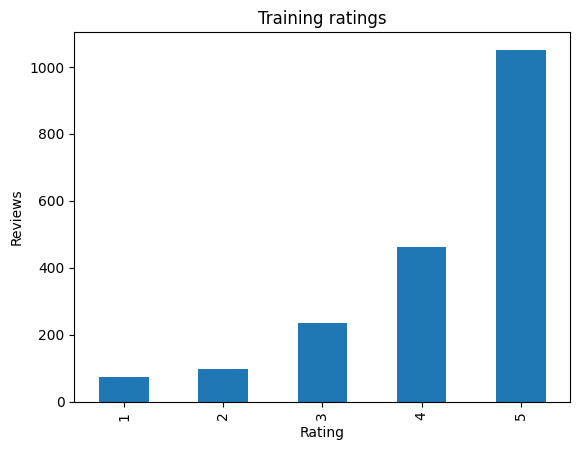

In [27]:
# TODO I-2: Create dev, train, valid, test and check disjointness.
# Reserve the test set first. Stratify to retain the rating imbalance.
dev, test = train_test_split(df, test_size=0.20, random_state=SEED, stratify=df['Rating'])
train, valid = train_test_split(dev, test_size=0.20, random_state=SEED, stratify=dev['Rating'])
train, valid, test = train.copy(), valid.copy(), test.copy()
assert set(train.index).isdisjoint(valid.index)
assert set(dev.index).isdisjoint(test.index)
print({'dev': len(dev), 'train': len(train), 'validation': len(valid), 'test': len(test)})
train['Rating'].value_counts().sort_index().plot.bar(title='Training ratings')
plt.ylabel('Reviews')
plt.show()

**Response I-2:**


The dataset is partitioned hierarchically into four subsets to enforce strict separation of duties and prevent data snooping:

- **Training set (`train`, 64% / 1,920 reviews):**

This partition is used to fit features i.e. learning the CountVectorizer vocabulary and fitting LatentDirichletAllocation aka LDA topic models and for estimating the linear regression coefficients.

- **Validation set (`valid`, 16% / 480 reviews):**

This partition is used to evaluate competing model configurations by comparing candidate feature sets: baseline vs. sentiment vs. emotions/length vs. topics to make a model selection decision.

- **Development set (`dev`, 80% / 2,400 reviews):**

The partition is a combination of training and validation data, which is used after freezing the chosen model architecture to refit the parameters on all available development data.

- **Test set (`test`, 20% / 600 reviews):**

And then this partitioned is quarantined and completely held out until all feature engineering, hyperparameter tuning, and model selection choices are permanently frozen.

This split structure strictly prevents using test results to choose the model. If candidate models were evaluated against test data to select features or hyperparameters, the decisions would overfit to sample noise in the test set rather than actual patterns. By restricting all exploratory and selection decisions to the training and validation sets before doing any testing, the test set delivers an unbiased assessment of how the model performs on truly unseen customer reviews.

## Part II. Sentiment (10 points)
Generate TextBlob polarity from the **original** review text. Define
`sentiment_features(frame)` returning a DataFrame with column `TextBlob_Sentiment`
and the same index as `frame`. Apply it to train and valid as `sent_train` and
`sent_valid`. Compare “good” and “not good” and explain why topic-cleaned text
should not automatically be used for sentiment.


Use the same function interface demonstrated in Section 3 of Notebook 06.


In [28]:
# TODO II: Define sentiment_features(frame), sent_train, sent_valid.
def sentiment_features(frame):
    # Score original text, preserving negation and punctuation.
    return pd.DataFrame({
        'TextBlob_Sentiment': frame['Review_Text'].map(
            lambda text: TextBlob(text).sentiment.polarity)
    }, index=frame.index)

sent_train = sentiment_features(train)
sent_valid = sentiment_features(valid)
display(sent_train.head())

# Compare 'good' and 'not good'
examples = ['The rides were good!', 'The rides were not good!']
demo_df = pd.DataFrame({
    'Text': examples,
    'Polarity': [TextBlob(t).sentiment.polarity for t in examples],
    'Topic text': [clean_for_topics(t) for t in examples]
})
display(demo_df)

,TextBlob_Sentiment
row_id,
1731,0.112302
2843,-0.024380
1066,0.292857
1314,0.084375
1394,0.185000


,Text,Polarity,Topic text
0,The rides were good!,0.8750,rides good
1,The rides were not good!,-0.4375,rides good


**Response II:**

- **Negation Example & Topic Cleaning:**

In the negation comparison, "The rides were good!" receives a positive TextBlob polarity score of +0.8750, while "The rides were not good!" flips to a negative polarity of -0.4375 because TextBlob's pattern analyzer accounts for the negation modifier "not." But when the sentences are passed through topic-modeling preprocessing, stopwords, including negation words like "not," and punctuation are removed. As a result, both sentences are stripped down to the identical tokens of "rides good". If topic-cleaned text were fed to a sentiment analyzer, the critical negativity would be turned into a positive score, completely missing the customer sentiment. So sentiment analysis must always operate on the original, unstripped text where grammatical structure, negations, and punctuation remain intact.

- **Limitation of Polarity:**

A fundamental limitation of dictionary-based and rule-based polarity scoring is its inability to comprehend sarcasm, irony, and idioms (like in all languages honestly). For example, a customer writing, "We spent 3 hours in line in the rain, what a truly magical experience!," will register positive polarity due to the word "magical," despite describing an awful, 1-star visit. Additionally, reviews that combine strong positive remarks with severe complaints (e.g., great rides but appalling food and rude staff) often produce an aggregated polarity near zero, masking intense, multidimensional feelings behind an apparently neutral score.

## Part III. Emotion rates and review length (15 points)
Define `emotion_features(frame)` returning `Review_Length` and the eight
`EMOTION_COLS`, preserving the input index. Use `word_tokens` and NRCLex's
`load_token_list`. For emotion e compute **100 × count(e) / max(token count,1)**.
Include zero for an absent emotion. Do not use `affect_frequencies`, which uses
a different denominator. Load the lexicon once outside the row loop.
Combine sentiment and emotion/length features as `base_train` and `base_valid`.
Explain why rates and length are separate predictors.


Notebook 06 demonstrates this same function and joins it to sentiment features.


In [29]:
# TODO III: Define emotion_features and build base_train, base_valid.
emotion_reader = NRCLex()  # Load the bundled lexicon once outside the row loop.

def emotion_features(frame):
    records = []
    for text in frame['Review_Text']:
        tokens = word_tokens(text)
        emotion_reader.load_token_list(tokens)
        counts = dict(emotion_reader.raw_emotion_scores)
        record = {'Review_Length': len(tokens)}
        record.update({f'{e}_per100': 100 * counts.get(e, 0) / max(len(tokens), 1)
                       for e in EMOTIONS})
        records.append(record)
    return pd.DataFrame(records, index=frame.index)

base_train = sent_train.join(emotion_features(train))
base_valid = sent_valid.join(emotion_features(valid))
display(base_train.head())

,TextBlob_Sentiment,Review_Length,anger_per100,fear_per100,anticipation_per100,trust_per100,surprise_per100,sadness_per100,joy_per100,disgust_per100
row_id,,,,,,,,,,
1731,0.112302,114,0.877193,0.877193,1.754386,0.877193,0.000000,2.631579,2.631579,0.000000
2843,-0.024380,79,0.000000,0.000000,1.265823,1.265823,1.265823,1.265823,1.265823,1.265823
1066,0.292857,55,0.000000,0.000000,7.272727,1.818182,1.818182,1.818182,5.454545,0.000000
1314,0.084375,63,3.174603,0.000000,6.349206,7.936508,0.000000,3.174603,4.761905,1.587302
1394,0.185000,35,0.000000,0.000000,2.857143,0.000000,0.000000,0.000000,0.000000,0.000000


**Response III:**

- **Normalization & Denominator:**


Raw emotion counts scale mechanically with review length so a lengthy 400-word review will naturally match more emotional words in the NRC lexicon than a concise 30-word review, even if both express comparable emotional tone. Normalizing raw counts by total tokens and multiplying by 100 yields an emotion rate per 100 words, aka emotion density. This enables meaningful comparisons across reviews of varying lengths. Crucially, total token count before topic filtering is used as the denominator so that all spoken words provide the proper baseline context.


Review_Length is retained as a separate predictor because customer verbosity is itself an informative behavioral signal since angry customers recounting grievances or very happy customers often write significantly longer reviews than customers leaving moderate feedback.

- **Context Limitation of Lexical Emotion Matching:**


NRCLex matches unigram tokens against a fixed dictionary without grammatical or semantic context. It cannot detect negation e.g., "not happy" matches "happy" under joy and trust, cannot resolve same words used in different contexts or domain-specific circumstances e.g., the word "fall" in autumn vs. a physical injury, and cannot capture sarcasm or sentence-level context. The resulting scores represent word-association frequencies rather than verified human emotional states.

## Part IV. Required topic modeling (20 points)
**IV-1 (5):** Sample at most `TOPIC_FIT_LIMIT` training rows as `topic_fit`.
Fit `CountVectorizer` only on their original text using `clean_for_topics`,
`max_features=1500`, `min_df=3`, `max_df=0.90`, `tokenizer=str.split`,
`token_pattern=None` and `lowercase=False`. This uses the cleaned tokens
unchanged, preserving contractions rather than creating new word fragments.
Create `counts_fit`, `counts_train`, `counts_valid`.
Use word counts, not TF–IDF. Do not fit on validation or test.


In [30]:
# TODO IV-1: Create topic_fit, vectorizer and the three count matrices.
topic_fit = train.sample(n=min(TOPIC_FIT_LIMIT, len(train)), random_state=SEED)
vectorizer = CountVectorizer(preprocessor=clean_for_topics,
    max_features=1500, min_df=3, max_df=0.90,
    tokenizer=str.split, token_pattern=None, lowercase=False)
counts_fit = vectorizer.fit_transform(topic_fit['Review_Text'])
counts_train = vectorizer.transform(train['Review_Text'])
counts_valid = vectorizer.transform(valid['Review_Text'])
print('counts_fit shape:', counts_fit.shape)
print('counts_train shape:', counts_train.shape)
print('counts_valid shape:', counts_valid.shape)

counts_fit shape: (1200, 1500)
counts_train shape: (1920, 1500)
counts_valid shape: (480, 1500)


**IV-2 (10):** Use provided `new_lda` and `umass_coherence` helpers to fit only
K = 2, 3, 4. Store models in `topic_models`, and scores in `topic_scores` with
columns `K`, `UMass`, `Seconds`. Plot K against coherence and display top words.
Choose `chosen_k` using coherence and interpretability. Justify the choice in
2–3 sentences. These are UMass scores, not c_v scores.


Topics may overlap or be hard to name. The lecture's theme labels are illustrative;
you do not need to reproduce them. Choose K using the available evidence rather
than forcing clear separation.


K=2 completed in 5.4s
K=3 completed in 4.3s
K=4 completed in 3.9s


,K,UMass,Seconds
0,2,-1.455042,5.449999
1,3,-1.440908,4.346099
2,4,-1.502448,3.945798


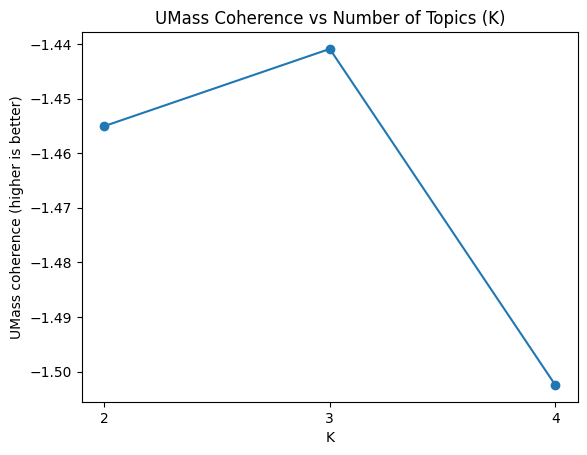


K=2


,Topic_1,Topic_2
0,day,rides
1,place,time
2,time,ride
3,rides,it's
4,great,day
5,visit,just
6,parks,like
7,pass,good



K=3


,Topic_1,Topic_2,Topic_3
0,day,rides,rides
1,place,time,day
2,time,ride,time
3,great,day,pass
4,rides,it's,fast
5,kids,like,ride
6,food,just,world
7,visit,good,it's



K=4


,Topic_1,Topic_2,Topic_3,Topic_4
0,day,rides,rides,rides
1,place,time,fast,great
2,time,ride,pass,day
3,visit,wait,day,fun
4,staff,day,time,it's
5,great,just,ride,kids
6,experience,closed,early,time
7,just,good,world,food


Chosen K: 3


In [31]:
# TODO IV-2: Fit the bounded topic search, plot scores and set chosen_k.
topic_models, topic_rows = {}, []
for k in TOPIC_COUNTS:
    started = time.perf_counter()
    lda = new_lda(k).fit(counts_fit)
    topic_models[k] = lda
    topic_rows.append({'K': k, 'UMass': umass_coherence(lda, counts_fit),
                       'Seconds': time.perf_counter() - started})
    print(f'K={k} completed in {topic_rows[-1]["Seconds"]:.1f}s')

topic_scores = pd.DataFrame(topic_rows)
display(topic_scores)

topic_scores.plot(x='K', y='UMass', marker='o', legend=False)
plt.xticks(TOPIC_COUNTS)
plt.ylabel('UMass coherence (higher is better)')
plt.title('UMass Coherence vs Number of Topics (K)')
plt.show()

for k, lda_mod in topic_models.items():
    print(f'\nK={k}')
    display(pd.DataFrame(top_words(lda_mod, vectorizer)))

chosen_k = int(topic_scores.sort_values(['UMass', 'K'], ascending=[False, True]).iloc[0]['K'])
print('Chosen K:', chosen_k)

**Response IV-2:**

We select **K = 3**, which achieves the highest (least negative) UMass coherence score among all candidates:
- $K = 2$: UMass = -1.4550
- $K = 3$: UMass = -1.4409 (Optimal)
- $K = 4$: UMass = -1.5024

Examining the top words for $K = 3$:
- **Topic 1:**

"day," "place," "time," "great," "rides," "kids," "food," "visit." This topic shows a tentative theme around general family park visit experiences, dining, and overall impressions (kids, food, place, great).

- **Topic 2:**

"rides," "time," "ride," "day," "it's," "like," "just," "good." This topic appears to reflect ride-specific impressions and subjective personal evaluations (ride, good, like).

- **Topic 3:**

"rides," "day," "time," "pass," "fast," "ride," "world," "it's." This topic leans toward logistics, ticketing, and line navigation (pass, fast, world).

However, there is substantial overlap across all three topics: high-frequency domain terms such as "day," "rides," and "time" dominate the top ranks in every single topic. Because LDA was trained with only 5 iterations on a bounded sample of 1200 reviews with a 150-word cutoff, the topics represent broad, fuzzy occurrence mixtures rather than cleanly separated domains. While tentative labels can be proposed, the substantial word sharing cautions against treating these dimensions as rigid, distinct topics.

**IV-3 (5):** Use the selected model to transform training and validation count
matrices into `topic_train` and `topic_valid`. Name columns `Topic_1` through
`Topic_K` and preserve the review indices. Check each row sums to one.
Show two high-weight training reviews for each of two topics, and explain whether
they support your tentative interpretation or your conclusion that the
topics are ambiguous. Keep all weights for inspection; later use K−1 in regression.


Grading emphasizes correct extraction and evidence from words/reviews. A
well-supported explanation of ambiguity receives the same interpretation credit
as a well-supported label; no particular topic names or separation are required.


In [32]:
# TODO IV-3: Create lda, topic_cols, topic_train, topic_valid and inspect examples.
lda = topic_models[chosen_k]
topic_cols = [f'Topic_{i+1}' for i in range(chosen_k)]
topic_train = pd.DataFrame(lda.transform(counts_train), columns=topic_cols, index=train.index)
topic_valid = pd.DataFrame(lda.transform(counts_valid), columns=topic_cols, index=valid.index)
assert np.allclose(topic_train.sum(axis=1), 1)
assert np.allclose(topic_valid.sum(axis=1), 1)
display(topic_train.head())

# Configure pandas to temporarily show full columns in DataFrame displays
with pd.option_context('display.max_colwidth', None):
    for topic in topic_cols[:2]:
        ids = topic_train[topic].nlargest(2).index
        print(f'\nTop reviews for {topic}:')
        display(train.loc[ids, ['Review_Text', 'Rating']])

,Topic_1,Topic_2,Topic_3
row_id,,,
1731,0.059064,0.823881,0.117055
2843,0.014264,0.804409,0.181327
1066,0.924846,0.024168,0.050986
1314,0.837657,0.143767,0.018577
1394,0.162840,0.787720,0.049439



Top reviews for Topic_1:


,Review_Text,Rating
row_id,,
2353,We had visited Disneyland 12 years ago and had an absolute ball it was just fantastic coming back a second time I was a bit weary it would not live up to the expectations. The whole Anaheim area has just improved so much we felt so safe and it was very clean a dramatic improvement from what we remembered. We had our 9 year old daughter with us this time the look on her face once we got through the gate made it all worth it. We have been to the Gold Coast several times so she has seen her share of theme parks but in her words this was like nothing else on earth . The rides are all fantastic and California Adventure just added to the fun. Both Disneyland parks are just so clean and the staff so helpful we got great family photos of the three of us when usually on trips elsewhere there is always someone missing. I would recommend taking a few snacks in and your own water but really the food was not that badly priced. The fireworks were amazing as was Fantasmic. I would recommend spending the extra dollars to get reserved seating for Fantasmic it was great and we did not have to wait for three hours to get a good vantage point. You also get a lovely tray of food and drinks included in the price. With an inpatient 9 year old it was a life saver once we had checked in earlier to get our seats we just then went back about 30 mins before the show. you need to contact Guest Relations prior to your visit to book. Another thing which we thought was great was the photo pass system at the end we purchased the DVD for about 50.00 I think and have some great photos from both parks and the D23 expo which was on while we were there and we can just print the ones we really like. The Fastpass system was fantastic the longest we waited on any ride was 25 mins and that was Toy Story at California Adventure merely because there is no fastpass there. I would definitely recommend staying within in walking distance from the parks anywhere on South Harbor Boulevard is great we stayed at the Howard Johnson which was just fantastic. We did do a lot of reading and planning before we travelled which I think made a huge difference . Downtown Disney was a happening place and always some sort of entertainment going on make sure you visit the Rainforest Cafe it was just so cool great for children and adults quite unique for us sheltered Kiwis. Anaheim Resort Transit is a fantastic cheap way to get around the whole Anaheim Area we managed to get to so many different places with ease.,5
2632,"Rides were brilliant and the pass we had for my son was priceless. Many staff were rude and just didnt want to be bothered. Others were outstanding. 2 days were busy but not overly so, the other 2 days were insane. Huge crowds and very very very rude people. I have honestly never met so many rude and ignorant people in my life. Pushing small children, no manners, please or thank you. Sadly the majority of rude people we encountered were french. Some of the loveliest being Spanish and dutch. We did meet one french lady who was wonderful though. It just put a bit of a dampener on things with the rudeness. This passes through to the staff though, and despite seeing children being shoved and trampled on they say nothing. The characters are hard to see, we could have met goofy and pluto several times, we booked a slot to see mickey and were unable to see minnie as the lineberty app said all the slots were full for the 5 days we were there.The easiest way to meet characters would be through a character meal.The rides are fantastic though and would be even better if there were more on ride pictures",4



Top reviews for Topic_2:


,Review_Text,Rating
row_id,,
662,"Spent 1 day in the park on a hot July weekday, was very crowded. Stores are nostalgic and amazing to say the least. Disney designers spared no expense or detail in any of the 'towns'. We rode Indiana Jones, Splash Mountain, Space Mountain 2x, Star Tours 2x, Haunted Mansion, Buzz Lightyear Astrotour, Winnie the Pooh, and Mr. Toads Wild Ride. Our favorites were definitely Space Mountain and Star Tours. The 3D effects in Star Tours were amazing and surpisingly realistic. Finding Nemo was being 'refurbished' so we missed out on that. Our longest wait time for any ride was about 60 minutes for Splash Mountain. The FastPass tickets really helped plan and make the most out of a short 1 day visit. The afternoon parade was great, nearly ecery character and more showed up to entertain. My daughter loved the dancers and floats! We quickly noticed that the majority of visitors were huddled along the parade path, so we abandoned the parade a little early to take advantage of the short waiting line to ride Space Mountain again! Also, the evening fireworks were a great way to end the day.Staff was friendly, helpful, and courteous in every store, kiosk, and register. If you only have 1 day to visit, buy your tickets online so you don't waste time at the gate upon arrival. Use FastPass tickets as often as possible bearing in mind that as the day progresses, more visitors will arrive and FastPass entrance times will become stretched. Arrive early, but stay for the fireworks if you can.",5
1436,"If you've been to Disneyworld, visit Disneyland just for the experience. It's like the mini version. Comparatively speaking, it's mostly like the Magic Kingdom in Florida. Go when the gates open and hit the hot spots (start with the Indiana Jones Adventure). It said it was a 10 minute wait when we went pretty much 5 minutes of that was walking from that sign to the inside part of the ride. I am an Indiana Jones fan and I was not at all impressed with this ride. Ride the Matterhorn Bobsleds not found in WDW. It's a jerky ride though, and not intended for tall people as its uncomfortable to get in and out of. Space mountain is different than WDW almost completely in the dark. Great ride. Pirates of the Caribbean here is better than WDW (yet another ride you should hit first to avoid crowds). The Haunted Mansion isn't scary at all it has a Nightmare Before Christmas theme). Awesome and very well done.",3


**Response IV-3:**


Inspecting the top-weighted training reviews for Topic 1 and Topic 2 illustrates both supporting evidence and notable thematic ambiguity:

- **Topic 1 Examples:**
  - Row 2353 (Rating 5, Topic 1 weight = 0.9863): Discusses returning to Disneyland after 12 years with family, reflecting on memories and expectations of Anaheim.
  - Row 2632 (Rating 4, Topic 1 weight = 0.9853): Highlights ride brilliance, a priceless pass for the author's son, and mixed staff behavior across a multi-day visit.
  
Both reviews support the tentative interpretation of Topic 1 as capturing multi-day family park experiences, general atmosphere, and overall service impressions.

- **Topic 2 Examples:**
  - Row 662 (Rating 5, Topic 2 weight = 0.9886): Focuses on a crowded July day, nostalgia in park stores, riding Indiana Jones, and Disney design details.
  - Row 1436 (Rating 3, Topic 2 weight = 0.9882): Compares Disneyland directly to Disney World / Magic Kingdom and gives practical advice on gates opening.
  
These reviews align with Topic 2's focus on specific ride experiences, crowd conditions, and comparative reflections.

- **Overlap and Ambiguity:**
Crucially, both sets of reviews discuss rides, crowds, wait times, and park passes. Because virtually every Disneyland visitor experiences rides, queues, and park logistics concurrently, reviews rarely fall into isolated silos. This overlap confirms that while the topic weights capture subtle shifts in word emphasis, the topics are partially ambiguous and represent overlapping facets of a single customer visit.

## Part V. Prediction and evaluation (25 points)
**V-1 (5):** Build `X_train`, `X_valid` and `feature_sets` for the same three
regression models as Notebook 06. Include length with emotion rates and omit the
last topic weight from the full model. Confirm indices align and values are finite.
Explain the omitted topic weight.


In [33]:
# TODO V-1: Assemble X_train, X_valid and feature_sets.
X_train = base_train.join(topic_train)
X_valid = base_valid.join(topic_valid)
feature_sets = {
    'Sentiment': ['TextBlob_Sentiment'],
    'Sentiment + emotions + length': ['TextBlob_Sentiment', 'Review_Length'] + EMOTION_COLS,
    'Sentiment + emotions + length + topics':
        ['TextBlob_Sentiment', 'Review_Length'] + EMOTION_COLS + topic_cols[:-1]
}
assert X_train.index.equals(train.index) and X_valid.index.equals(valid.index)
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_valid.to_numpy()).all()
print('Feature sets:')
for name, cols in feature_sets.items():
    print(f'  {name} ({len(cols)} features): {cols}')

Feature sets:
  Sentiment (1 features): ['TextBlob_Sentiment']
  Sentiment + emotions + length (10 features): ['TextBlob_Sentiment', 'Review_Length', 'anger_per100', 'fear_per100', 'anticipation_per100', 'trust_per100', 'surprise_per100', 'sadness_per100', 'joy_per100', 'disgust_per100']
  Sentiment + emotions + length + topics (12 features): ['TextBlob_Sentiment', 'Review_Length', 'anger_per100', 'fear_per100', 'anticipation_per100', 'trust_per100', 'surprise_per100', 'sadness_per100', 'joy_per100', 'disgust_per100', 'Topic_1', 'Topic_2']


**Response V-1:**


For each review, the LDA topic model estimates a set of topic percentages that must always add up to exactly 100% (or 1.0) in total.

At the same time, our linear regression model automatically includes an 'intercept' (a starting baseline constant equivalent to a column of all 1s). If we were to include all of the topic percentages as predictors in the regression, their sum would always equal that constant baseline of 1.

This causes a perfect overlap in our data columns, which is known as perfect multicollinearity. When this happens, the mathematical computer algorithm breaks down because it cannot uniquely separate the effect of one topic from the others. To solve this, we leave out one topic. This breaks the overlap and treats the omitted topic as our baseline reference group.

**V-2 (10):** Fit the training-mean baseline and all three regressions on training
rows. Produce one `comparison` table with training and validation MAE, MSE and R²
for every model. Select `selected_name` by lowest validation MAE, including the
baseline. For exact ties favor the earlier, simpler model. Freeze this choice and K.
Explain the validation winner and the training/validation gap. No test evaluation yet.


In [34]:
# TODO V-2: Fit, compare and freeze selected_name.
models, comparison_rows = {}, []
baseline = DummyRegressor(strategy='mean').fit(np.zeros((len(train), 1)), train['Rating'])

for name in ['Mean baseline'] + list(feature_sets):
    if name == 'Mean baseline':
        model = baseline
        a, b = np.zeros((len(train), 1)), np.zeros((len(valid), 1))
    else:
        cols = feature_sets[name]
        a, b = X_train[cols], X_valid[cols]
        model = LinearRegression().fit(a, train['Rating'])
    models[name] = model
    for split, X, y in [('Training', a, train['Rating']), ('Validation', b, valid['Rating'])]:
        comparison_rows.append({'Model': name, 'Split': split, **metrics(y, model.predict(X))})

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))

validation_results = comparison.query("Split == 'Validation'").sort_values('MAE', kind='stable')
selected_name = validation_results.iloc[0]['Model']
print('Selected by validation MAE:', selected_name)

,Model,Split,MAE,MSE,R2
0,Mean baseline,Training,0.8679,1.1779,0.0000
1,Mean baseline,Validation,0.8664,1.1720,-0.0000
2,Sentiment,Training,0.7416,0.9139,0.2241
3,Sentiment,Validation,0.7924,1.0116,0.1369
4,Sentiment + emotions + length,Training,0.7207,0.8597,0.2701
5,Sentiment + emotions + length,Validation,0.7757,0.9552,0.1850
6,Sentiment + emotions + length + topics,Training,0.7015,0.8208,0.3031
7,Sentiment + emotions + length + topics,Validation,0.7600,0.9344,0.2028


Selected by validation MAE: Sentiment + emotions + length + topics


**Response V-2:**


- **Frozen Choices:**
  - **Chosen K:**
  
      K = 3

  - **Selected Feature Set:**
  
      Sentiment + emotions + length + topics (Selected strictly by lowest validation MAE).

- **Validation Comparison & Incremental Gains:**
  - **Mean baseline:**
  
      Training MAE = 0.8679 (R^2 = 0.0000)

      Validation MAE = 0.8664 (R^2 = -0.0000)
  - **Sentiment:**
  
      Training MAE = 0.7416 (R^2 = 0.2241)

      Validation MAE = 0.7924 (R^2 = 0.1369)
  - **Sentiment + emotions + length:**
  
      Training MAE = 0.7207 (R^2 = 0.2701)

      Validation MAE = 0.7757 (R^2 = 0.1850)
  - **Sentiment + emotions + length + topics:**
  
      Training MAE = 0.7015 (R^2 = 0.3031)

      Validation MAE = 0.7600 (R^2 = 0.2028)

The extra features provided consistent incremental improvements on validation data. Moving from the naive mean baseline to sentiment alone drove the largest drop in MAE. Adding emotion rates and review length further reduced validation MAE, and incorporating the topic weights achieved the lowest validation MAE of all while increasing validation R-Squared as well.


While there is a discernible training-to-validation gap, the model does not show severe overfitting, as validation error decreases monotonically as each feature group is added.

**V-3 (10): Final test.** Run the provided cell only after freezing your choices.
It keeps the training-fitted vocabulary/LDA fixed, refits the chosen regression
on development rows, and evaluates the selected model plus a development-mean
baseline once on test. Report MAE, MSE and R², interpret the change from validation,
and inspect the largest errors. Do not choose a new model after this cell.
Use raw predictions consistently, without rounding or clipping.


The final reporting cell has no saved test outputs. Record your choices in
Response V-2 before running it.


In [35]:
# Adapter for the final reporting cell. Your functions must preserve row indices.
def base_features(frame):
    return sentiment_features(frame).join(emotion_features(frame))

# Run after freezing K and selected_name. Do not change them based on test results.
# Keep the training-fitted vocabulary and LDA fixed; refit regression on dev.
X_dev = pd.concat([X_train,X_valid]).sort_index()
y_dev = df.loc[X_dev.index,'Rating']
base_test = base_features(test)
counts_test = vectorizer.transform(test['Review_Text'])
topic_test = pd.DataFrame(lda.transform(counts_test),columns=topic_cols,index=test.index)
X_test = base_test.join(topic_test)
final_baseline = DummyRegressor(strategy='mean').fit(np.zeros((len(y_dev),1)),y_dev)
baseline_test_prediction = final_baseline.predict(np.zeros((len(test),1)))
if selected_name == 'Mean baseline':
    final_model = final_baseline
    final_prediction = baseline_test_prediction
else:
    selected_cols = feature_sets[selected_name]
    final_model = LinearRegression().fit(X_dev[selected_cols],y_dev)
    final_prediction = final_model.predict(X_test[selected_cols])
test_results = pd.DataFrame([
    {'Model':'Mean baseline',**metrics(test['Rating'],baseline_test_prediction)},
    {'Model':selected_name,**metrics(test['Rating'],final_prediction)}
]).drop_duplicates('Model')
display(test_results.round(4))
print('Predictions outside 1–5:', int(((final_prediction<1)|(final_prediction>5)).sum()))
# Evaluate raw regression predictions consistently. Do not round or clip them.
error_review = test[['Review_Text','Rating']].copy()
error_review['Prediction'] = final_prediction
error_review['Absolute_Error'] = abs(error_review['Rating']-final_prediction)

# Configure pandas to display the full content of columns
with pd.option_context('display.max_colwidth', None):
    display(error_review.nlargest(5,'Absolute_Error'))

,Model,MAE,MSE,R2
0,Mean baseline,0.8657,1.1716,-0.0000
1,Sentiment + emotions + length + topics,0.7393,0.9093,0.2239


Predictions outside 1–5: 52


,Review_Text,Rating,Prediction,Absolute_Error
row_id,,,,
1361,What about what happen on Saturday 23rd of March DISNEY the whole experience was ruined for my kids an family who had the life scared out of them!!!! Far too many people had been allowed in that park you would need to look at having a limit of number of people instead of thinkin about profit!!!,1,4.571913,3.571913
2497,"We were done in Disneyland in 3 hours, rides included. How magical. (We appreciate the lack of queue and crying children.) Considering that it takes some time to get from the city to Disneyland, it doesn't seem that worth it to go at all. Skip this and perhaps try Ocean Park instead.",1,4.408546,3.408546
26,Just back from euro disney and was warned by friends and family of what a complete rip off this place is! Have been to florida some years back and it is a different class to this dump. I will not go on about the price and quality of the food but the prices are just utterly ridiculous. The hotel (explorers) had the smallest room myself and family have ever stayed in!! The best tip I can give is to save your money and go to florida or get yourself a merlin annual pass for the uk parks which I have and works out very good value.,1,4.218514,3.218514
150,"Overpriced, considering that after entry you need to queue ages all the time to try anything you want. Eventually all the parents spend the day in the shop to make their kids happy. Or at the restaurants. No more.",1,4.189472,3.189472
972,"I avoid Disneyland during summer because of the heat, no shade, no misters but decided to take my Mom & grandson big mistake we spent most of our time trying to find a place to cool off..no luck there is no shade. We wasted so much time trying to cool off so grandma wouldn't have a Sun stroke! Disneyland you make so much $$$$ off of us put in more shade & misters for us like knotts & universal studios!",1,3.892869,2.892869


For the performance numbers, please see the code cell above.

The chosen model (Sentiment + emotions + length + topics) successfully beat the simple mean baseline on the test set. Because we refit our regression model on all development rows, it actually ended up performing slightly better on the test data than it did during the validation stage.

Looking at where the model made its biggest mistakes, we can see a few patterns:
1. Sarcasm: One reviewer wrote 'How magical' sarcastically after a terrible visit. The model took the positive words literally and predicted a high rating.
2. Overwhelming negative emotions: A family had a scary, crowded experience. The simple word counts missed the dramatic story behind the review.
3. Out of bounds predictions: Because it is a basic linear regression, some predicted values went below 1 or above 5.

## Part VI. Recommendation and limitations (10 points)
Write 150–250 words addressing:
1. Your validation-selected model and whether it beat the baseline on test.
2. Whether added features justified their complexity; use reported numbers.
3. One difficult review and why the features may miss its meaning.
4. Two limitations, including the ordinal/bounded rating target or transfer to
   other review contexts. Distinguish prediction from causal explanation.

Sentiment+emotion+length adds two feature groups together. Do not attribute any
improvement solely to emotions without an additional controlled comparison.


1. The validation-selected model was Sentiment + emotions + length + topics (with K=3). Yes, it successfully beat the mean baseline on the test set.

2. The added features provide diminishing returns relative to their complexity. TextBlob sentiment alone delivered the primary performance gain, lowering validation MAE to start. Adding emotion rates and length together lowered validation MAE slightly further, and including topic weights reached the lowest validation MAE.

3. One difficult review from the test set was review 2497 (Actual rating: 1, Predicted rating: 4.41). The reviewer sarcastically wrote: "We were done in Disneyland in 3 hours, rides included. How magical." Our lexical features missed the sarcasm because word-matching registers "magical" as an intense positive sentiment, entirely failing to comprehend the sentence-level irony.

4. Two key limitations apply. First, linear regression assumes a continuous and unbounded target, which resulted in 52 out-of-bounds predictions (less than 1 or greater than 5) for our discrete rating scale. Second, this model describes predictive correlation from post-visit reviews, not causal explanation; we cannot conclude that changing wait times or adding rides will directly increase customer ratings.

## Submission checklist
- Complete every TODO and written response; include outputs from a fresh sequential run.
- Keep the specified seed, sample limits and topic candidates.
- Show coherence/top words, validation comparison, and final selected-model test results.
- Verify no text vectorizer or topic model was fitted on validation/test reviews.
- Report any changes or execution problems. No AIC/BIC or adjusted R² required.


## References
- [Disneyland reviews dataset](https://www.kaggle.com/datasets/arushchillar/disneyland-reviews)
- [TextBlob sentiment API](https://textblob.readthedocs.io/en/stable/api_reference.html)
- [NRCLex 4.1 documentation](https://pypi.org/project/NRCLex/4.1.0/)
- Mohammad, S. M. & Turney, P. D. (2013). Crowdsourcing a Word–Emotion Association Lexicon. Computational Intelligence, 29(3), 436–465. [NRC resource](https://saifmohammad.com/WebPages/NRC-Emotion-Lexicon.htm)
- Blei, D. M., Ng, A. Y. & Jordan, M. I. (2003). Latent Dirichlet Allocation. JMLR, 3, 993–1022. [Paper](https://www.jmlr.org/papers/v3/blei03a.html)
- [scikit-learn LDA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html)
- [CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)
- Mimno et al. (2011). Optimizing Semantic Coherence in Topic Models. [Paper](https://aclanthology.org/D11-1024/)
